# Deskripsi Library

In [2]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


# Memanggil Dataset

In [3]:
nama_file = "laptop_price.csv" if os.path.exists("laptop_price.csv") else "laptop_price2.csv"
df = pd.read_csv(nama_file)
print(f"Data berhasil dimuat dari {nama_file}!")
df.head()

Data berhasil dimuat dari laptop_price.csv!


,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


# Melihat Jumlah Baris dan Kolom|

In [4]:
print(f"jumlah baris: {df.shape[0]}")
print(f"jumlah kolom: {df.shape[1]}")
df.shape

jumlah baris: 1275
jumlah kolom: 15


(1275, 15)

# Informasi Dataset

In [5]:
df.info()
print("\n jumlah Missing values per kolom:")
print(df.isnull().sum())
print("\n Jumlah Duplikat: {}".format(df.duplicated().sum()))
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1275 non-null   object 
 1   Product              1275 non-null   object 
 2   TypeName             1275 non-null   object 
 3   Inches               1275 non-null   float64
 4   ScreenResolution     1275 non-null   object 
 5   CPU_Company          1275 non-null   object 
 6   CPU_Type             1275 non-null   object 
 7   CPU_Frequency (GHz)  1275 non-null   float64
 8   RAM (GB)             1275 non-null   int64  
 9   Memory               1275 non-null   object 
 10  GPU_Company          1275 non-null   object 
 11  GPU_Type             1275 non-null   object 
 12  OpSys                1275 non-null   object 
 13  Weight (kg)          1275 non-null   float64
 14  Price (Euro)         1275 non-null   float64
dtypes: float64(4), int64(1), object(10)
me

,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Price (Euro)
count,1275.000000,1275.000000,1275.000000,1275.000000,1275.000000
mean,15.022902,2.302980,8.440784,2.040525,1134.969059
std,1.429470,0.503846,5.097809,0.669196,700.752504
min,10.100000,0.900000,2.000000,0.690000,174.000000
25%,14.000000,2.000000,4.000000,1.500000,609.000000
50%,15.600000,2.500000,8.000000,2.040000,989.000000
75%,15.600000,2.700000,8.000000,2.310000,1496.500000
max,18.400000,3.600000,64.000000,4.700000,6099.000000


# Data Cleaning

In [8]:
kolom_teks = df.select_dtypes(include=['object']).columns.tolist()
for col in kolom_teks:
    df[col] = df[col].astype(str).str.strip()  # Menghapus spasi di awal dan akhir string

df = df.drop_duplicates().reset_index(drop=True)
print(f"Jumlah baris setelah menghapus duplikat: {df.shape[0]} baris, {df.shape[1]} kolom.")

Jumlah baris setelah menghapus duplikat: 1275 baris, 15 kolom.


# Exploraty Data Analys

# Pengecekan Missing Values & Kolerasi Antar Fitur

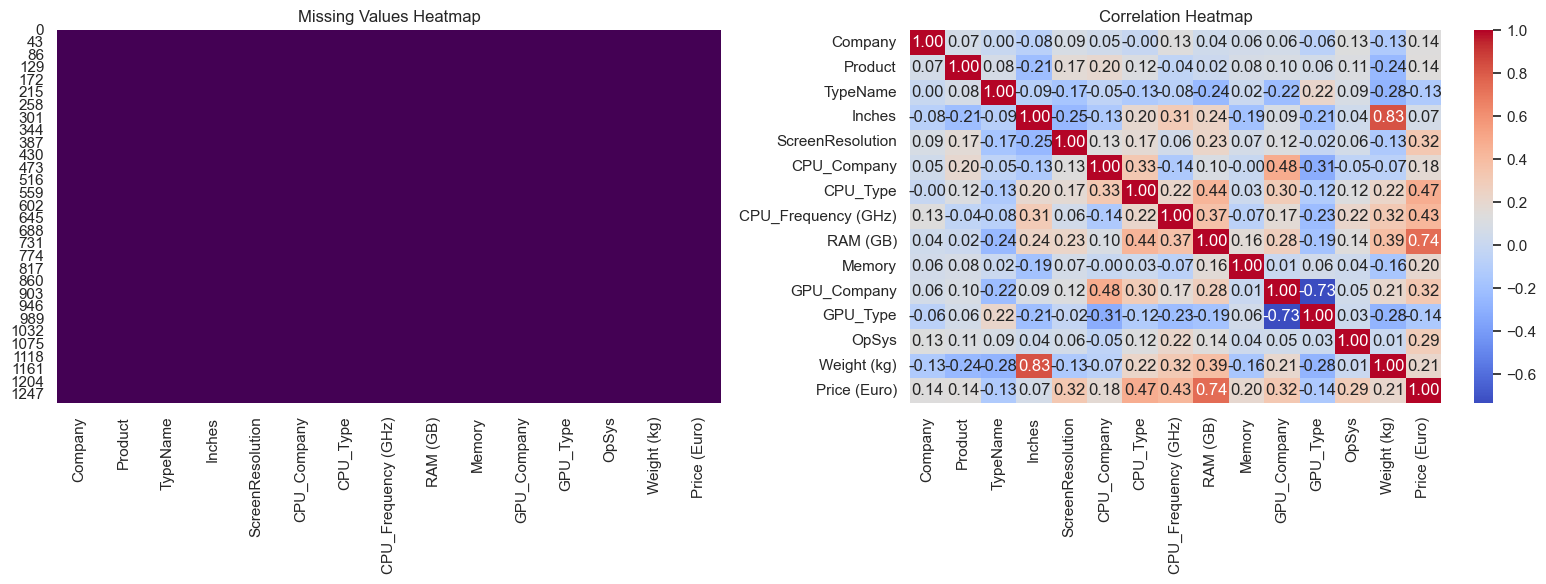

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Values Heatmap')

df_encoded = df.copy()
for col in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

# Jumlah Laptop dan Rata Rata Harga

,Company,jumlah,rata_rata_harga
0,Dell,291,1199.225120
1,Lenovo,289,1093.862215
2,HP,268,1080.314664
3,Asus,152,1123.829737
4,Acer,101,633.464455
5,MSI,54,1728.908148
6,Toshiba,48,1267.812500
7,Apple,21,1564.198571
8,Samsung,9,1413.444444
9,Razer,7,3346.142857


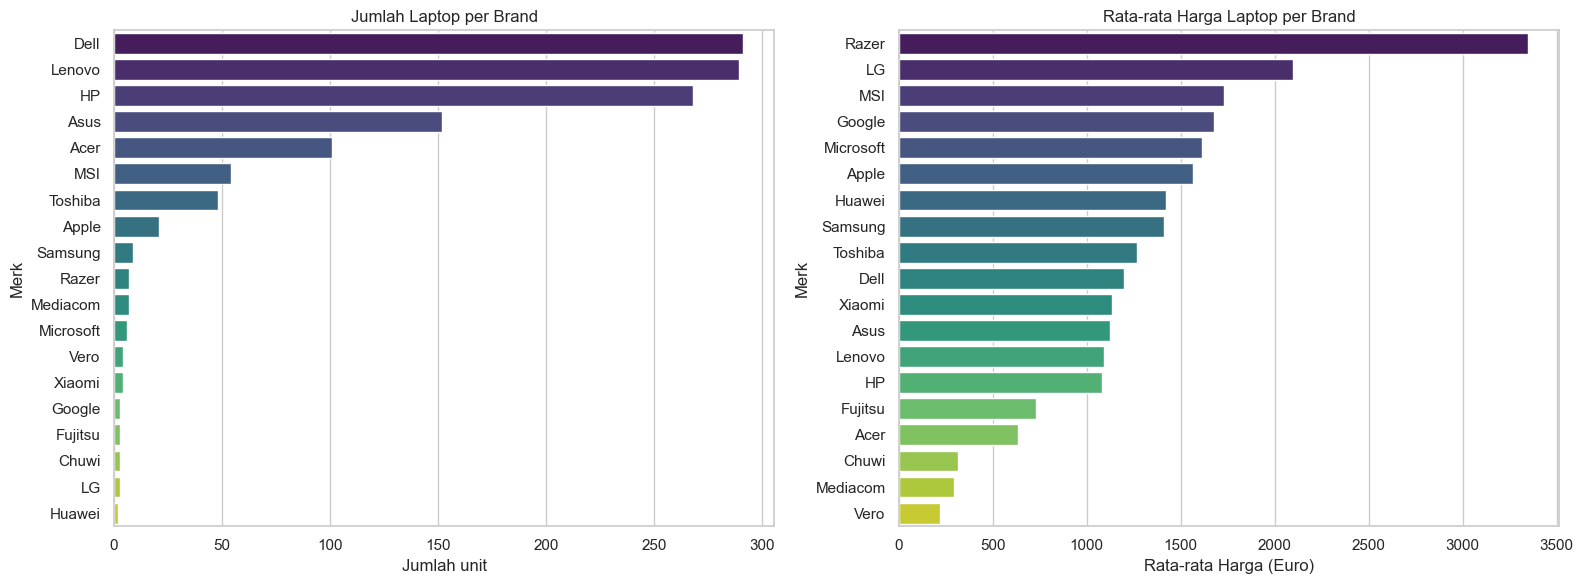

In [14]:
brand_stats = df.groupby("Company").agg(
    jumlah=("Price (Euro)", "count"),
    rata_rata_harga=("Price (Euro)", "mean"),
).sort_values(by="jumlah", ascending=False).reset_index()

display(brand_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=brand_stats, x="jumlah", y="Company", hue="Company", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Jumlah Laptop per Brand")
axes[0].set_xlabel("Jumlah unit")
axes[0].set_ylabel("Merk")

brand_stats_sorted = brand_stats.sort_values(by="rata_rata_harga", ascending=False)
sns.barplot(data=brand_stats_sorted, x="rata_rata_harga", y="Company", hue="Company", palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Rata-rata Harga Laptop per Brand")
axes[1].set_xlabel("Rata-rata Harga (Euro)")
axes[1].set_ylabel("Merk")

plt.tight_layout()
plt.show()

# Distribusi Tipe Laptop, RAM, Sistem Operasi

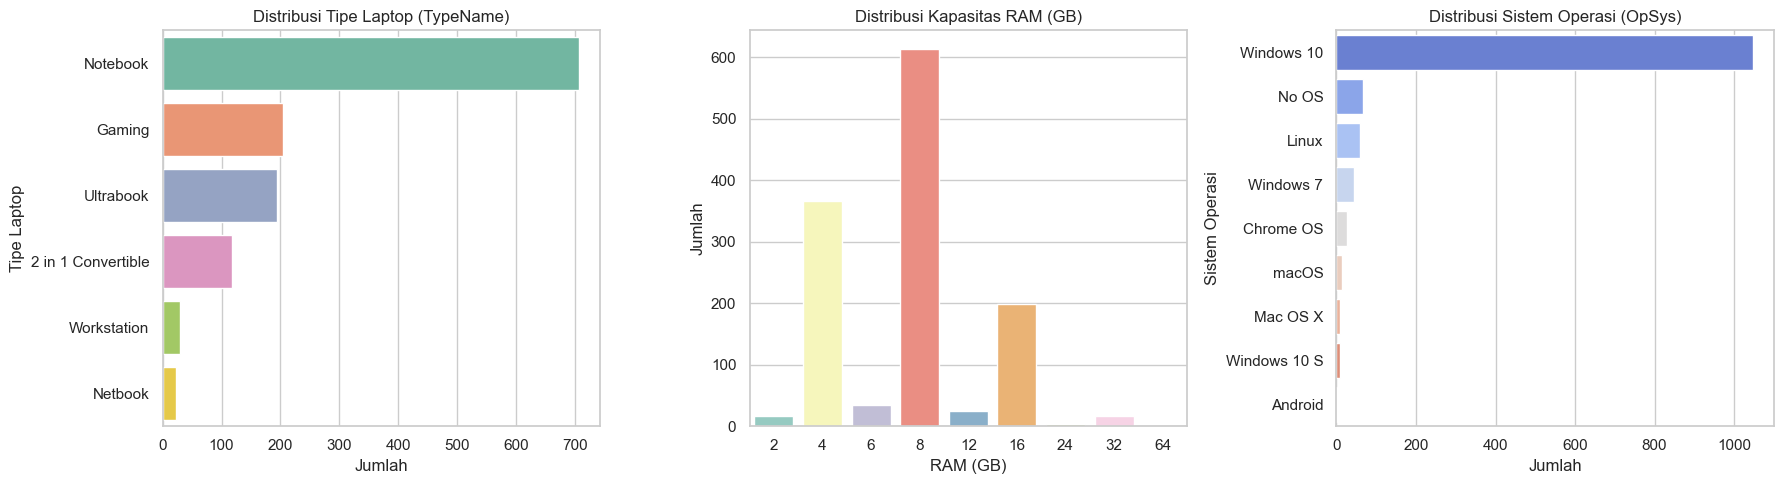

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, y="TypeName", order=df["TypeName"].value_counts().index, palette="Set2", ax=axes[0])
axes[0].set_title("Distribusi Tipe Laptop (TypeName)")
axes[0].set_xlabel("Jumlah")
axes[0].set_ylabel("Tipe Laptop")

sns.countplot(data=df, x="RAM (GB)", order=sorted(df["RAM (GB)"].unique()), palette="Set3", ax=axes[1])
axes[1].set_title("Distribusi Kapasitas RAM (GB)")
axes[1].set_xlabel("RAM (GB)")
axes[1].set_ylabel("Jumlah")

sns.countplot(data=df, y="OpSys", order=df["OpSys"].value_counts().index, palette="coolwarm", ax=axes[2])
axes[2].set_title("Distribusi Sistem Operasi (OpSys)")
axes[2].set_xlabel("Jumlah")
axes[2].set_ylabel("Sistem Operasi")

plt.tight_layout()
plt.show()

# Distribusi Harga Laptop & Pengaruh RAM Terhadap Harga

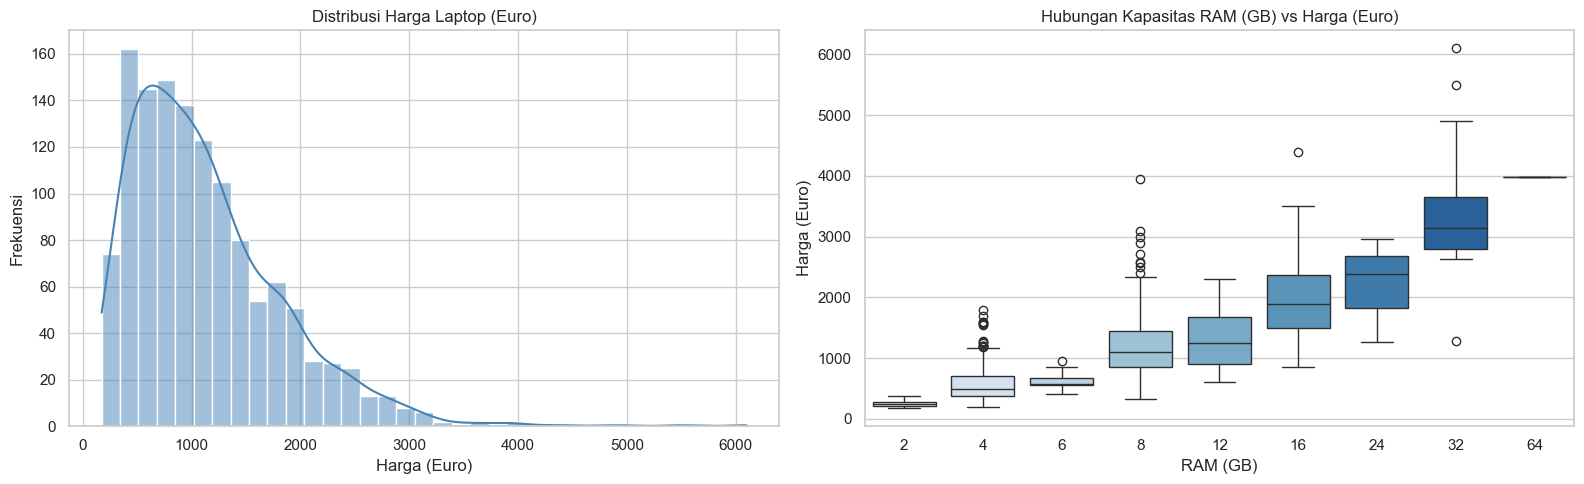

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df["Price (Euro)"], bins=35, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Distribusi Harga Laptop (Euro)")
axes[0].set_xlabel("Harga (Euro)")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(data=df, x="RAM (GB)", y="Price (Euro)", palette="Blues", ax=axes[1])
axes[1].set_title("Hubungan Kapasitas RAM (GB) vs Harga (Euro)")
axes[1].set_xlabel("RAM (GB)")
axes[1].set_ylabel("Harga (Euro)")

plt.tight_layout()
plt.show()

# Train-Tes, Split

In [20]:
fitur_kategorikal = [
    "Company",
    "Product",
    "TypeName",
    "ScreenResolution",
    "CPU_Company",
    "CPU_Type",
    "Memory",
    "GPU_Company",
    "GPU_Type",
    "OpSys"
]

fitur_numerik = [
    "Inches",
    "CPU_Frequency (GHz)",
    "RAM (GB)",
    "Weight (kg)"
]

X = df[fitur_kategorikal + fitur_numerik]
y = df["Price (Euro)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Ukuran Data Latih (X_train): {X_train.shape}")
print(f"Ukuran Data Uji (X_test)   : {X_test.shape}")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), fitur_numerik),
        ("cat", OneHotEncoder(handle_unknown="ignore"), fitur_kategorikal)
    ]
)

Ukuran Data Latih (X_train): (1020, 14)
Ukuran Data Uji (X_test)   : (255, 14)


# Pemodelan & Evaluasi Model

In [21]:
daftar_model = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
}

hasil_evaluasi = []
pipeline_terlatih = {}

for nama_model, algoritma in daftar_model.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", algoritma)
    ])
    
    pipe.fit(X_train, y_train)
    pipeline_terlatih[nama_model] = pipe
    
    y_pred = pipe.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    hasil_evaluasi.append({
        "Algoritma": nama_model,
        "R2 Score": round(r2, 4),
        "Akurasi (%)": f"{r2 * 100:.2f}%",
        "MAE (Euro)": round(mae, 2),
        "RMSE (Euro)": round(rmse, 2)
    })

df_evaluasi = pd.DataFrame(hasil_evaluasi).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
display(df_evaluasi)

,Algoritma,R2 Score,Akurasi (%),MAE (Euro),RMSE (Euro)
0,Gradient Boosting Regressor,0.8910,89.10%,170.37,232.57
1,Random Forest Regressor,0.8738,87.38%,168.41,250.28
2,Linear Regression,0.8188,81.88%,204.57,299.90


# Visualisasi Perbandingan Harga Aktual dan Prediksi

Model Terbaik: Gradient Boosting Regressor (Akurasi R2 = 89.10%)


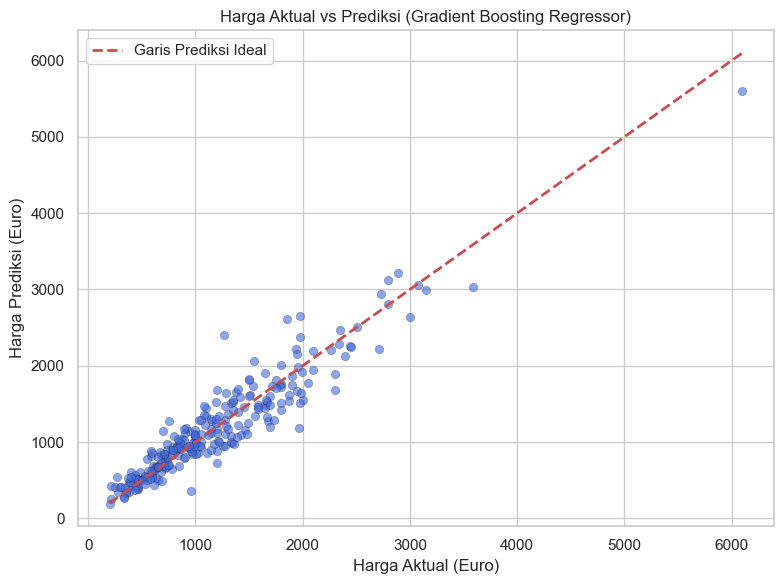

In [22]:
nama_model_terbaik = df_evaluasi.loc[0, "Algoritma"]
best_model = pipeline_terlatih[nama_model_terbaik]
print(f"Model Terbaik: {nama_model_terbaik} (Akurasi R2 = {df_evaluasi.loc[0, 'Akurasi (%)']})")

y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6, color="royalblue", edgecolors="k", linewidth=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Garis Prediksi Ideal")
plt.title(f"Harga Aktual vs Prediksi ({nama_model_terbaik})")
plt.xlabel("Harga Aktual (Euro)")
plt.ylabel("Harga Prediksi (Euro)")
plt.legend()
plt.tight_layout()
plt.show()

# Uji Coba Data dan Menyimpan Model

In [23]:
# Contoh uji coba prediksi 1 data laptop
contoh_laptop = pd.DataFrame([{
    "Company": "Apple",
    "Product": "MacBook Pro",
    "TypeName": "Ultrabook",
    "Inches": 13.3,
    "ScreenResolution": "IPS Panel Retina Display 2560x1600",
    "CPU_Company": "Intel",
    "CPU_Type": "Core i5",
    "CPU_Frequency (GHz)": 2.3,
    "RAM (GB)": 8,
    "Memory": "128GB SSD",
    "GPU_Company": "Intel",
    "GPU_Type": "Iris Plus Graphics 640",
    "OpSys": "macOS",
    "Weight (kg)": 1.37
}])

prediksi_contoh = best_model.predict(contoh_laptop)[0]
print(f"Contoh Prediksi Harga Apple MacBook Pro: EUR {prediksi_contoh:,.2f}")

# Menyimpan model terbaik
joblib.dump(best_model, "model_laptop.joblib")

# Menyimpan daftar pilihan unik untuk dropdown semua kolom (kecuali CPU_Type) di main.py
product_by_company = {
    comp: sorted(df[df["Company"] == comp]["Product"].unique().tolist())
    for comp in sorted(df["Company"].unique().tolist())
}

metadata = {
    "Company": sorted(df["Company"].unique().tolist()),
    "Product": sorted(df["Product"].unique().tolist()),
    "product_by_company": product_by_company,
    "TypeName": sorted(df["TypeName"].unique().tolist()),
    "Inches": sorted(df["Inches"].unique().tolist()),
    "ScreenResolution": sorted(df["ScreenResolution"].unique().tolist()),
    "CPU_Company": sorted(df["CPU_Company"].unique().tolist()),
    "CPU_Frequency (GHz)": sorted(df["CPU_Frequency (GHz)"].unique().tolist()),
    "RAM (GB)": sorted(df["RAM (GB)"].unique().tolist()),
    "Memory": sorted(df["Memory"].unique().tolist()),
    "GPU_Company": sorted(df["GPU_Company"].unique().tolist()),
    "GPU_Type": sorted(df["GPU_Type"].unique().tolist()),
    "OpSys": sorted(df["OpSys"].unique().tolist()),
    "Weight (kg)": sorted(df["Weight (kg)"].unique().tolist())
}

joblib.dump(metadata, "metadata_laptop.joblib")
print("Berhasil menyimpan 'model_laptop.joblib' dan 'metadata_laptop.joblib'!")

Contoh Prediksi Harga Apple MacBook Pro: EUR 1,364.91
Berhasil menyimpan 'model_laptop.joblib' dan 'metadata_laptop.joblib'!
